<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/BRAIN_RUMOR_MRI_Quando_uma_Rede_Convolucional_Aprende_a_Olhar_o_C%C3%A9rebro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Passo 1 — Conectar o Google Drive e localizar o arquivo

O conjunto de dados foi baixado do Kaggle como `archive.zip` e guardado no Google Drive do autor, na pasta `BRAIN TUMOR MRI - by Euripedes Gomes`. O comando `drive.mount` conecta o Drive ao Colab (pede autorização da conta Google na primeira execução), e o Drive passa a ser acessível como uma pasta em `/content/drive/MyDrive/`.

As duas linhas de `print` conferem que o arquivo foi encontrado e que o tamanho bate com o esperado (cerca de 164,7 MB). Essa conferência evita trabalhar, sem perceber, com um arquivo diferente do que foi auditado.

In [1]:
# Passo 1 — Conectar o Google Drive ao Colab e localizar o archive.zip
import os
from google.colab import drive

drive.mount('/content/drive')

ZIP_DRIVE = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/archive.zip'

print('Arquivo existe?', os.path.exists(ZIP_DRIVE))
print('Tamanho (MB)  :', round(os.path.getsize(ZIP_DRIVE) / 1e6, 1))

Mounted at /content/drive
Arquivo existe? True
Tamanho (MB)  : 164.7


## Passo 2 — Descompactar as imagens e preparar a pasta do relatório

O Drive montado é lento para ler milhares de arquivos pequenos. Por isso o zip é copiado para o disco local da máquina do Colab (`/content/`) e descompactado em `/content/data`. Esse disco é apagado ao fim da sessão, mas o zip original permanece no Drive, bastando repetir os Passos 1 e 2 para reconstruir tudo.

A célula também cria a pasta `relatorio/` dentro da pasta do projeto no Drive. Todas as figuras (`fig01_...png`) e tabelas (`tab01_...csv`) geradas ao longo do notebook serão gravadas nela, prontas para o relatório final.

Como alguns zips do Kaggle trazem uma pasta-raiz extra, as pastas `Training` e `Testing` são localizadas com `glob` em qualquer nível. A lista de classes vem dos nomes das subpastas — no dataset, o nome da pasta é o rótulo.

In [2]:
# Passo 2 — Descompactar o archive.zip no disco local do Colab e criar a pasta do relatório
import zipfile, shutil, glob

PASTA_PROJETO = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes'
RELATORIO_DIR = PASTA_PROJETO + '/relatorio'   # figuras e tabelas para o Word
ZIP_LOCAL     = '/content/archive.zip'
DATA_DIR      = '/content/data'

os.makedirs(RELATORIO_DIR, exist_ok=True)
shutil.copy(ZIP_DRIVE, ZIP_LOCAL)             # copia o zip do Drive para o disco do Colab
zipfile.ZipFile(ZIP_LOCAL).extractall(DATA_DIR)

TRAIN_DIR = glob.glob(DATA_DIR + '/**/Training', recursive=True)[0]
TEST_DIR  = glob.glob(DATA_DIR + '/**/Testing',  recursive=True)[0]
CLASSES   = sorted(os.listdir(TRAIN_DIR))

print('Pasta do relatório:', RELATORIO_DIR)
print('Training          :', TRAIN_DIR)
print('Testing           :', TEST_DIR)
print('Classes           :', CLASSES)

Pasta do relatório: /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/relatorio
Training          : /content/data/Training
Testing           : /content/data/Testing
Classes           : ['glioma', 'meningioma', 'notumor', 'pituitary']


**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

## Passo 3 — Ambiente de execução, versões e sementes

O critério 1 do professor pede linguagem, versões, bibliotecas e ambiente. Esta célula importa as bibliotecas que serão usadas em todo o notebook (NumPy, Pandas, Matplotlib, Pillow, scikit-learn e TensorFlow/Keras) e imprime a versão de cada uma, além de verificar se há GPU disponível.

A célula também fixa a semente (`SEED = 42`) no Python, no NumPy e no TensorFlow. A semente controla tudo o que envolve sorteio — embaralhamento das imagens, divisão treino/validação, inicialização dos pesos da rede — para que uma nova execução reproduza os mesmos resultados. A reprodutibilidade completa em GPU não é garantida (algumas operações da GPU são não determinísticas), e isso será declarado como limitação no relatório.

**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

In [3]:
# Passo 3 — Ambiente de execução, versões das bibliotecas e sementes
import sys, random, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
from tensorflow import keras

# Sementes fixas para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Python       :', platform.python_version())
print('TensorFlow   :', tf.__version__)
print('Keras        :', keras.__version__)
print('NumPy        :', np.__version__)
print('Pandas       :', pd.__version__)
print('Matplotlib   :', matplotlib.__version__)
print('Pillow       :', PIL.__version__)
print('scikit-learn :', sklearn.__version__)
print('GPU          :', tf.config.list_physical_devices('GPU'))
print('Semente      :', SEED)

Python       : 3.13.16
TensorFlow   : 2.21.0
Keras        : 3.13.2
NumPy        : 2.4.6
Pandas       : 2.2.3
Matplotlib   : 3.10.0
Pillow       : 11.3.0
scikit-learn : 1.6.1
GPU          : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semente      : 42


**Observação:** o ambiente é o Google Colab com GPU NVIDIA T4, Python 3.13.16, TensorFlow 2.21.0, Keras 3.13.2, NumPy 2.4.6, Pandas 2.2.3, Matplotlib 3.10.0, Pillow 11.3.0 e scikit-learn 1.6.1, com semente fixa 42. Estas versões são as que constarão na seção de ambiente do relatório e no README do repositório.

### Bibliotecas utilizadas

Cada biblioteca resolve um problema específico da cadeia que vai do arquivo de imagem ao resultado da rede.

**Python 3.13** — linguagem em que todo o notebook é escrito; padrão de fato em ciência de dados e aprendizado profundo.

**Pillow 11.3** (Clark et al., 2015) — *abrir as imagens.* Um JPEG é um formato comprimido; o Pillow o descompacta em pixels, lê dimensões e modo de cor, converte para tons de cinza e redimensiona. É a porta entre o arquivo no disco e a matemática.

**NumPy 2.4** (Harris et al., 2020) — *calcular.* Uma imagem 128×128 é uma matriz de 16.384 números; o NumPy opera sobre matrizes inteiras de uma só vez, o que torna viável o processamento de milhares de imagens. Todas as estatísticas da análise exploratória são calculadas com ele.

**Pandas 2.2** (McKinney, 2010) — *organizar em tabelas.* Equivale a uma planilha dentro do Python: contagens por classe, tabelas de qualidade dos dados e a comparação entre experimentos, exportadas em CSV para o relatório.

**Matplotlib 3.10** (Hunter, 2007) — *desenhar.* Transforma números em figuras com título, eixos e legenda: distribuição das classes, exemplos de imagens, curvas de treino e validação e matriz de confusão, gravadas em PNG.

**TensorFlow 2.21** (Abadi et al., 2016) — *treinar.* É o motor do aprendizado profundo: calcula automaticamente os gradientes de milhões de parâmetros (retropropagação) e executa as operações na GPU.

**Keras 3.13** (Chollet et al., 2015) — *descrever a rede.* Interface de alto nível sobre o TensorFlow: a CNN é definida camada a camada, com função de perda, otimizador e métricas, sem programar a matemática do treinamento.

**scikit-learn 1.6** (Pedregosa et al., 2011) — *dividir e avaliar.* Faz a divisão estratificada entre treino e validação e calcula as métricas com a definição correta: acurácia, precisão, revocação, F1 e matriz de confusão. Não treina a rede; atua antes e depois dela.

**Google Colab** — ambiente de execução em nuvem que hospeda o notebook e fornece a GPU NVIDIA T4.

As referências completas de cada biblioteca, no formato NBR 6023, constarão na lista final do relatório, na ordem da primeira citação.

## Definição do problema

**Tarefa.** Classificação de imagens de ressonância magnética cerebral em quatro categorias: *glioma*, *meningioma*, *pituitary* e *notumor*. Da mesma saída deriva-se a leitura binária entre presença e ausência de tumor, sem treinar outra rede. Ficam fora do escopo a segmentação, a localização do tumor, o grau, o prognóstico e qualquer uso clínico.

**Entrada e resposta.** A entrada é uma imagem de RM, padronizada para 128×128 pixels em tons de cinza. A resposta é a classe da imagem, codificada como um vetor de quatro probabilidades (uma por classe), cuja maior probabilidade define a predição.

**Por que uma CNN.** Uma imagem é uma matriz de pixels cuja informação está na relação espacial entre vizinhos. Achatá-la em vetor para uma rede densa descartaria essa estrutura e elevaria o número de parâmetros; filtros convolucionais com pesos compartilhados detectam padrões locais em qualquer posição, e o pooling resume a informação espacial.

**Pergunta de pesquisa.** Em que medida uma CNN simples, avaliada sem vazamento entre treinamento, validação e teste, classifica corretamente as quatro categorias, e como as decisões de treinamento e regularização contribuem para sua generalização?

**Objetivo geral.** Desenvolver e avaliar uma CNN para a classificação de imagens de RM cerebral em quatro categorias, com avaliação final em conjunto de teste preservado.

**Objetivos específicos.** (i) Caracterizar o conjunto e auditar sua qualidade, incluindo duplicidades e possível vazamento entre os subconjuntos; (ii) construir a rede e treiná-la com validação independente; (iii) comparar configurações de taxa de aprendizado, Early Stopping, Dropout e aumento de dados; (iv) avaliar o desempenho com acurácia, precisão, revocação, F1 e matriz de confusão, incluindo a leitura binária.

## Passo 4 — Distribuição das imagens por subconjunto e classe

O critério 1 pede o número de observações e a distribuição das classes. Esta célula conta as imagens de cada classe em `Training` e `Testing`, monta a tabela de contagem e desenha o primeiro gráfico do trabalho.

A contagem serve a dois propósitos. Primeiro, conferir se o arquivo analisado reproduz o levantamento do documento de definição (1.400 imagens por classe no Training e 400 no Testing, 7.200 no total). Segundo, verificar o balanceamento: classes equilibradas dispensam técnicas de compensação (pesos de classe ou reamostragem) e permitem usar a acurácia como métrica principal sem distorção.

A tabela é gravada em `relatorio/tab01_distribuicao_classes.csv` e o gráfico em `relatorio/fig01_distribuicao_classes.png`, os primeiros itens do relatório final.

Subconjunto  Training  Testing  Total
Classe                               
glioma           1400      400   1800
meningioma       1400      400   1800
notumor          1400      400   1800
pituitary        1400      400   1800
Total            5600     1600   7200


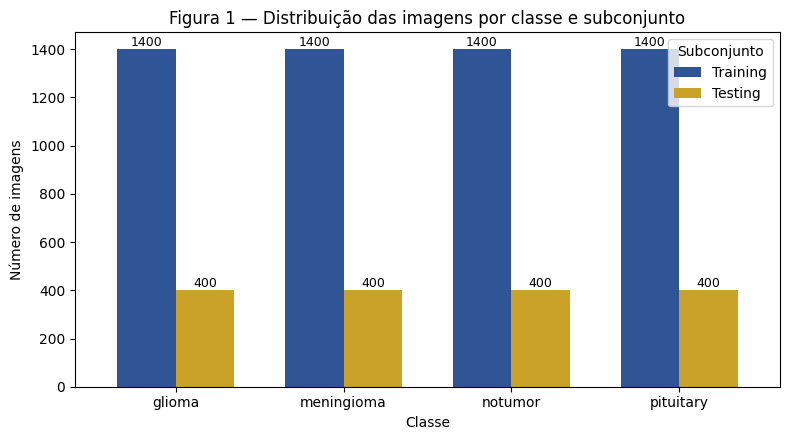

In [4]:
# Passo 4 — Contagem de imagens por subconjunto e classe, tabela e gráfico
SUBSETS = {'Training': TRAIN_DIR, 'Testing': TEST_DIR}

linhas = []
for nome, pasta in SUBSETS.items():
    for cls in CLASSES:
        n = len(os.listdir(os.path.join(pasta, cls)))
        linhas.append({'Subconjunto': nome, 'Classe': cls, 'Imagens': n})

contagem = (pd.DataFrame(linhas)
              .pivot(index='Classe', columns='Subconjunto', values='Imagens')
              [['Training', 'Testing']])
contagem['Total'] = contagem.sum(axis=1)
contagem.loc['Total'] = contagem.sum()

print(contagem)
contagem.to_csv(os.path.join(RELATORIO_DIR, 'tab01_distribuicao_classes.csv'))

# Gráfico de barras agrupadas (sem a linha Total)
dados = contagem.drop(index='Total')[['Training', 'Testing']]
fig, ax = plt.subplots(figsize=(8, 4.5))
dados.plot(kind='bar', ax=ax, color=['#2F5597', '#C9A227'], width=0.7)
ax.set_title('Figura 1 — Distribuição das imagens por classe e subconjunto')
ax.set_xlabel('Classe')
ax.set_ylabel('Número de imagens')
ax.legend(title='Subconjunto')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig01_distribuicao_classes.png'), dpi=200)
plt.show()

**Observação:** a contagem reproduz integralmente o levantamento do documento de definição: 1.400 imagens por classe no Training (5.600) e 400 por classe no Testing (1.600), totalizando 7.200. As quatro classes são perfeitamente balanceadas nos dois subconjuntos, o que dispensa pesos de classe ou reamostragem e autoriza o uso da acurácia como métrica principal, complementada por precisão, revocação e F1 por classe. A contagem difere da descrição pública do dataset (7.023 imagens), e por isso todas as estatísticas deste trabalho se referem ao arquivo efetivamente analisado. Tabela e figura gravadas em `relatorio/tab01_distribuicao_classes.csv` e `relatorio/fig01_distribuicao_classes.png`.